# Cartographie des données

1. Modèle de données · 2. Grain des tables · 3. Lignage des colonnes · 4. Intégrité des liens · 5. Flux de traitement

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.max_colwidth", None)
DATA_DIR = Path("../docs")  # même dossier que les autres notebooks

schedule_brut = pd.read_csv(DATA_DIR / "released_schedule.csv", encoding="utf-8-sig", parse_dates=["date"])
schedule = schedule_brut[schedule_brut["date"] < "2027-01-01"]  # 01/01/2027 écarté (usine fermée fin décembre)
besoins = schedule[schedule["schedule_quantity"] > 0]
distances = pd.read_csv(DATA_DIR / "distances.csv", encoding="utf-8-sig")
grille = pd.read_csv(DATA_DIR / "rate_sheet.csv", dtype={"km_up_to": str}).set_index("km_up_to")

## 1. Modèle de données
Chaque boîte est une entité, avec sa clé et son effectif. Un trait plein = lien par clé (1 → N). Un trait vert pointillé = lecture de la grille par intervalle.

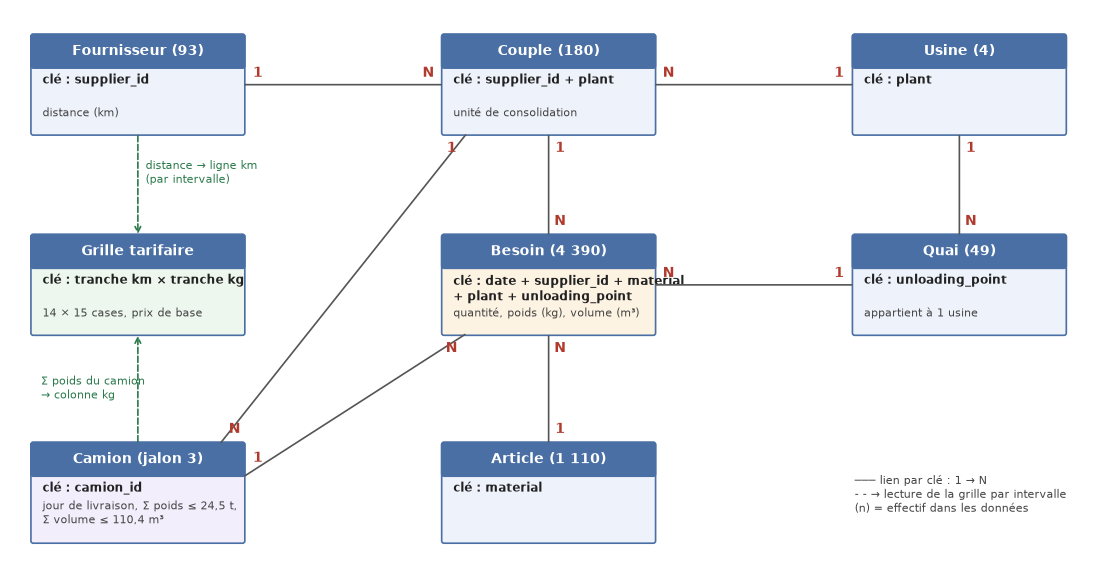

In [6]:
n = {
    "Fournisseur": besoins["supplier_id"].nunique(), "Usine": besoins["plant"].nunique(),
    "Quai": besoins["unloading_point"].nunique(), "Article": besoins["material"].nunique(),
    "Besoin": len(besoins), "Couple": besoins.groupby(["supplier_id", "plant"]).ngroups,
}
fmt = lambda x: f"{x:,}".replace(",", " ")

fig, ax = plt.subplots(figsize=(14, 7.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.2); ax.axis("off")
W, H = 2.7, 1.25
P = {"Fournisseur": (0.3, 5.6), "Couple": (5.6, 5.6), "Usine": (10.9, 5.6),
     "Grille": (0.3, 3.0), "Besoin": (5.6, 3.0), "Quai": (10.9, 3.0),
     "Camion": (0.3, 0.3), "Article": (5.6, 0.3)}

def entite(cle_pos, titre, cle, attributs="", couleur="#eef3fb"):
    x, y = P[cle_pos]
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.03", fc=couleur, ec="#4a6fa5", lw=1.2))
    ax.add_patch(FancyBboxPatch((x, y + H - 0.38), W, 0.38, boxstyle="round,pad=0.03", fc="#4a6fa5", ec="#4a6fa5", lw=1.2))
    ax.text(x + W / 2, y + H - 0.19, titre, ha="center", va="center", fontsize=10, color="white", weight="bold")
    ax.text(x + 0.12, y + H - 0.48, cle, fontsize=8.5, va="top", weight="bold", color="#222")
    ax.text(x + 0.12, y + 0.18, attributs, fontsize=8, va="bottom", color="#444")

def lien(a, b, pos_1, pos_n):
    ax.annotate("", b, a, arrowprops=dict(arrowstyle="-", color="#555", lw=1.2))
    ax.text(*pos_1, "1", fontsize=10, weight="bold", color="#b03a2e", ha="center", va="center")
    ax.text(*pos_n, "N", fontsize=10, weight="bold", color="#b03a2e", ha="center", va="center")

entite("Fournisseur", f"Fournisseur ({n['Fournisseur']})", "clé : supplier_id", "distance (km)")
entite("Couple", f"Couple ({n['Couple']})", "clé : supplier_id + plant", "unité de consolidation")
entite("Usine", f"Usine ({n['Usine']})", "clé : plant")
entite("Besoin", f"Besoin ({fmt(n['Besoin'])})", "clé : date + supplier_id + material\n+ plant + unloading_point",
       "quantité, poids (kg), volume (m³)", couleur="#fdf3e3")
entite("Quai", f"Quai ({n['Quai']})", "clé : unloading_point", "appartient à 1 usine")
entite("Article", f"Article ({fmt(n['Article'])})", "clé : material")
entite("Camion", "Camion (jalon 3)", "clé : camion_id",
       "jour de livraison, Σ poids ≤ 24,5 t,\nΣ volume ≤ 110,4 m³", couleur="#f3eefb")
entite("Grille", "Grille tarifaire", "clé : tranche km × tranche kg", "14 × 15 cases, prix de base", couleur="#eef7ee")

cx = lambda k: P[k][0] + W / 2
cy = lambda k: P[k][1] + H / 2
haut, bas, gauche, droite = (lambda k: P[k][1] + H), (lambda k: P[k][1]), (lambda k: P[k][0]), (lambda k: P[k][0] + W)
lien((droite("Fournisseur"), cy("Fournisseur")), (gauche("Couple"), cy("Couple")),
     (droite("Fournisseur") + 0.2, cy("Fournisseur") + 0.15), (gauche("Couple") - 0.2, cy("Couple") + 0.15))
lien((gauche("Usine"), cy("Usine")), (droite("Couple"), cy("Couple")),
     (gauche("Usine") - 0.2, cy("Usine") + 0.15), (droite("Couple") + 0.2, cy("Couple") + 0.15))
lien((cx("Couple"), bas("Couple")), (cx("Besoin"), haut("Besoin")),
     (cx("Couple") + 0.15, bas("Couple") - 0.2), (cx("Besoin") + 0.15, haut("Besoin") + 0.2))
lien((cx("Usine"), bas("Usine")), (cx("Quai"), haut("Quai")),
     (cx("Usine") + 0.15, bas("Usine") - 0.2), (cx("Quai") + 0.15, haut("Quai") + 0.2))
lien((gauche("Quai"), cy("Quai")), (droite("Besoin"), cy("Besoin")),
     (gauche("Quai") - 0.2, cy("Quai") + 0.15), (droite("Besoin") + 0.2, cy("Besoin") + 0.15))
lien((cx("Article"), haut("Article")), (cx("Besoin"), bas("Besoin")),
     (cx("Article") + 0.15, haut("Article") + 0.2), (cx("Besoin") + 0.15, bas("Besoin") - 0.2))
# Couple → Camion (un couple remplit plusieurs camions) et Camion → Besoin (un camion contient plusieurs lignes)
lien((gauche("Couple") + 0.3, bas("Couple")), (droite("Camion") - 0.3, haut("Camion")),
     (gauche("Couple") + 0.1, bas("Couple") - 0.2), (droite("Camion") - 0.1, haut("Camion") + 0.2))
lien((droite("Camion"), cy("Camion") + 0.2), (gauche("Besoin") + 0.3, bas("Besoin")),
     (droite("Camion") + 0.2, cy("Camion") + 0.45), (gauche("Besoin") + 0.1, bas("Besoin") - 0.2))

vert = dict(arrowstyle="->", color="#2b7a4b", lw=1.2, ls="--")
ax.annotate("", (cx("Grille"), haut("Grille")), (cx("Fournisseur"), bas("Fournisseur")), arrowprops=vert)
ax.text(cx("Grille") + 0.1, 4.95, "distance → ligne km\n(par intervalle)", fontsize=8, color="#2b7a4b")
ax.annotate("", (cx("Grille"), bas("Grille")), (cx("Camion"), haut("Camion")), arrowprops=vert)
ax.text(cx("Grille") - 1.25, 2.15, "Σ poids du camion\n→ colonne kg", fontsize=8, color="#2b7a4b")
ax.text(10.9, 0.9, "─── lien par clé : 1 → N\n- - → lecture de la grille par intervalle\n(n) = effectif dans les données",
        fontsize=8, color="#444", va="center")
plt.show()

**Lecture.** Le **Besoin** est au centre : chaque ligne relie un fournisseur, un article, un quai (donc une usine) et un jour. Les besoins d'un même **couple** fournisseur × usine sont consolidés ensemble. Le volume dépend du **conteneur** (article × quai), pas de la quantité. Le prix se lit dans la grille par **intervalles** : la ligne vient de la distance du fournisseur, la colonne du poids total du camion, donc après regroupement.

## 2. Grain des tables
Ce que représente une ligne à chaque étape, et combien il y en a.

In [4]:
feries = pd.to_datetime(["2026-11-11"])
jour_livraison = besoins["date"].where(~besoins["date"].isin(feries), besoins["date"] - pd.offsets.BDay(1))
livraisons_actuelles = besoins.assign(date=jour_livraison).groupby(["supplier_id", "plant", "date"]).ngroups

pd.DataFrame([
    ("1. Planning brut", "fournisseur × article × usine × quai × date", len(schedule_brut)),
    ("2. Sans le 01/01", "idem", len(schedule)),
    ("3. Besoins (quantité > 0)", "idem", len(besoins)),
    ("4. Livraisons actuelles", "couple × jour (11/11 → veille)", livraisons_actuelles),
    ("5. Couples", "fournisseur × usine", besoins.groupby(["supplier_id", "plant"]).ngroups),
    ("6. Camions", "un camion ≤ 24,5 t et 110,4 m³", "algorithme (jalon 3)"),
    ("Sortie 1", "couple : profil de livraison", besoins.groupby(["supplier_id", "plant"]).ngroups),
    ("Sortie 2", "camion × article × quai", "algorithme (jalon 3)"),
    ("Sortie 3", "couple, puis total : économie", "algorithme (jalon 3)"),
], columns=["étape", "une ligne =", "lignes"]).set_index("étape")

,une ligne =,lignes
étape,,
1. Planning brut,fournisseur × article × usine × quai × date,5728
2. Sans le 01/01,idem,5308
3. Besoins (quantité > 0),idem,4390
4. Livraisons actuelles,couple × jour (11/11 → veille),1634
5. Couples,fournisseur × usine,180
6. Camions,"un camion ≤ 24,5 t et 110,4 m³",algorithme (jalon 3)
Sortie 1,couple : profil de livraison,180
Sortie 2,camion × article × quai,algorithme (jalon 3)
Sortie 3,"couple, puis total : économie",algorithme (jalon 3)


## 3. Lignage des colonnes
Ce que devient chaque colonne source, jusqu'aux sorties.

| Colonne source | Transformation | Sert à | Sortie |
|---|---|---|---|
| `supplier_id` + `plant` | regroupement | couple : profil, camions | 1, 2, 3 |
| `date` | 11/11 → veille ; dernier jour du profil ≤ date | date de livraison ; anticipation ≤ 7 jours | 1, 2 |
| `schedule_quantity` | filtre > 0 | quantité de chaque article dans le camion | 2 |
| `weight` | Σ par camion | capacité 24,5 t ; colonne kg de la grille | 2, 3 |
| `volume` | Σ par camion | capacité 110,4 m³ | 2 |
| `material`, `unloading_point` | conservés tels quels | contenu et quais desservis par le camion | 2 |
| `distance` | jointure sur `supplier_id` | ligne km de la grille | 3 |
| grille, marge, diesel | lecture par intervalles × (1 + marge) × diesel | coût d'un camion | 3 |
| `transmission_date`, `version_date` | non utilisées | – | – |

## 4. Intégrité des liens
Chaque lien du modèle est vérifié sur les données.

In [5]:
fournisseurs = besoins["supplier_id"].drop_duplicates()
controles = [
    ("Besoin → Fournisseur : fournisseurs trouvés dans distances.csv",
     f"{fournisseurs.isin(distances['supplier_id']).sum()} / {len(fournisseurs)}"),
    ("Fournisseur → distance : distance renseignée",
     f"{fournisseurs.isin(distances.dropna()['supplier_id']).sum()} / {len(fournisseurs)}"),
    ("distances.csv : fournisseurs sans aucun besoin", int((~distances["supplier_id"].isin(fournisseurs)).sum())),
    ("Quai → Usine : usines max par quai", int(besoins.groupby("unloading_point")["plant"].nunique().max())),
    ("Conteneur : volumes différents max par article × quai",
     int(besoins.dropna(subset=["volume"]).groupby(["material", "unloading_point"])["volume"].nunique().max())),
    ("Fournisseurs livrant plusieurs usines",
     f"{int((besoins.groupby('supplier_id')['plant'].nunique() > 1).sum())} / {len(fournisseurs)}"),
    ("Articles livrés à plusieurs usines",
     f"{int((besoins.groupby('material')['plant'].nunique() > 1).sum())} / {besoins['material'].nunique()}"),
    ("Clé du besoin unique (doublons)", int(besoins.duplicated(["date", "supplier_id", "material", "plant", "unloading_point"]).sum())),
]
pd.DataFrame(controles, columns=["contrôle", "résultat"]).set_index("contrôle")

,résultat
contrôle,
Besoin → Fournisseur : fournisseurs trouvés dans distances.csv,93 / 93
Fournisseur → distance : distance renseignée,92 / 93
distances.csv : fournisseurs sans aucun besoin,63
Quai → Usine : usines max par quai,1
Conteneur : volumes différents max par article × quai,1
Fournisseurs livrant plusieurs usines,52 / 93
Articles livrés à plusieurs usines,95 / 1110
Clé du besoin unique (doublons),0
